# Lab 2: A neural network from scratch
Machine Learning [CII5SE039CI], Group 03

The task is to classify handwritten digits using a network with two hidden
layers. I use NumPy for the network and scikit-learn only for loading and
splitting the data. There is no automatic differentiation.

In [1]:
from pathlib import Path
from time import perf_counter
import csv
import platform

import numpy as np
import matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

Path("results").mkdir(exist_ok=True)
print("Python:", platform.python_version())
print("NumPy:", np.__version__, "scikit-learn:", sklearn.__version__)


def save_csv(filename, rows):
    with open(Path("results") / filename, "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)

Python: 3.12.14
NumPy: 2.5.4 scikit-learn: 1.9.1


## 1. Dataset
Each image has 8 x 8 pixels, so there are 64 input features. Pixel values
are between 0 and 16. Dividing by 16 puts them in the range [0, 1].
A one-hot label has ten entries, with 1 at the correct digit and 0 elsewhere.
Stratification keeps similar class proportions in the two sets.

In [2]:
digits = load_digits()
X = digits.data.astype(np.float64) / 16.0
y = digits.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42
)
Y_train = np.eye(10)[y_train]
Y_test = np.eye(10)[y_test]

print("Training:", X_train.shape, Y_train.shape)
print("Test:    ", X_test.shape, Y_test.shape)
print("Input range:", X.min(), "to", X.max())
print("Example label:", y_train[0], "->", Y_train[0])
assert X_train.shape == (1257, 64)
assert X_test.shape == (540, 64)
assert np.all(Y_train.sum(axis=1) == 1)

Training: (1257, 64) (1257, 10)
Test:     (540, 64) (540, 10)
Input range: 0.0 to 1.0
Example label: 0 -> [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


## 2. Network design

`64 inputs -> W neurons -> ReLU -> W neurons -> ReLU -> 10 outputs -> softmax`

| Parameter | W = 16 | W = 64 |
| --- | --- | --- |
| W1 | (64, 16) | (64, 64) |
| b1 | (16,) | (64,) |
| W2 | (16, 16) | (64, 64) |
| b2 | (16,) | (64,) |
| W3 | (16, 10) | (64, 10) |
| b3 | (10,) | (10,) |

For a batch of m examples, the hidden activations have shape (m, W) and
the output has shape (m, 10). Biases are added to every row.
I interpret the manual's N(0, 0.01) as mean 0 and standard deviation 0.01
(`normal(0, 0.01)` in NumPy). Biases start at zero.
ReLU is max(0, z), so it introduces nonlinearity.

In [3]:
def initialise(width, seed=42):
    rng = np.random.default_rng(seed)
    return {
        "W1": rng.normal(0, 0.01, (64, width)),
        "b1": np.zeros(width),
        "W2": rng.normal(0, 0.01, (width, width)),
        "b2": np.zeros(width),
        "W3": rng.normal(0, 0.01, (width, 10)),
        "b3": np.zeros(10),
    }

## 3. Forward pass and cross-entropy

The forward equations are:

$$Z_1=XW_1+b_1,\quad A_1=\mathrm{ReLU}(Z_1)$$
$$Z_2=A_1W_2+b_2,\quad A_2=\mathrm{ReLU}(Z_2)$$
$$Z_3=A_2W_3+b_3,\quad P=\mathrm{softmax}(Z_3)$$

Softmax changes the scores into probabilities:
$$P_{ik}=\frac{e^{Z_{3,ik}}}{\sum_j e^{Z_{3,ij}}}.$$
I subtract each row's maximum before exponentiation to avoid overflow.
This does not change softmax probabilities.

The average cross-entropy is
$$L=-\frac{1}{m}\sum_i\sum_k Y_{ik}\log P_{ik}.$$
In the code I calculate log probabilities directly from the shifted scores.
This avoids taking log(0). Before training, probabilities should be close
to 0.1, so the loss should be close to -log(0.1) = 2.3026.

In [4]:
def forward(X_batch, params):
    Z1 = X_batch @ params["W1"] + params["b1"]
    A1 = np.maximum(0, Z1)
    Z2 = A1 @ params["W2"] + params["b2"]
    A2 = np.maximum(0, Z2)
    Z3 = A2 @ params["W3"] + params["b3"]

    shifted = Z3 - Z3.max(axis=1, keepdims=True)
    exp_scores = np.exp(shifted)
    P = exp_scores / exp_scores.sum(axis=1, keepdims=True)
    cache = (X_batch, Z1, A1, Z2, A2, Z3, P)
    return P, cache


def cross_entropy(scores, Y_batch):
    shifted = scores - scores.max(axis=1, keepdims=True)
    log_probs = shifted - np.log(np.exp(shifted).sum(axis=1, keepdims=True))
    return -np.mean(np.sum(Y_batch * log_probs, axis=1))


for width in [16, 64]:
    params = initialise(width)
    P, cache = forward(X_train[:32], params)
    loss = cross_entropy(cache[5], Y_train[:32])
    assert P.shape == (32, 10)
    assert np.allclose(P.sum(axis=1), 1, atol=1e-6, rtol=0)
    assert abs(loss - np.log(10)) < 0.01
    print(f"W={width}: shape={P.shape}, row sum error="
          f"{np.max(np.abs(P.sum(axis=1) - 1)):.2e}, loss={loss:.6f}")

W=16: shape=(32, 10), row sum error=2.22e-16, loss=2.302595
W=64: shape=(32, 10), row sum error=3.33e-16, loss=2.302623


## 4. Backpropagation: chain rule

For one example, softmax has derivative
$$\frac{\partial P_k}{\partial z_j}=P_k(\delta_{kj}-P_j).$$
Combining this with cross-entropy gives
$$\frac{\partial L_i}{\partial z_j}
=-\sum_k\frac{Y_k}{P_k}P_k(\delta_{kj}-P_j)=P_j-Y_j.$$
The labels sum to one. Averaging over a batch adds a factor 1/m.

Start at the output and work backwards. Here D means the derivative of
the loss with respect to an intermediate value, and * is elementwise multiplication.

$$D_3=(P-Y)/m$$
$$\frac{\partial L}{\partial W_3}=A_2^T D_3,\quad
\frac{\partial L}{\partial b_3}=\sum_i D_{3,i}$$
$$D_2=(D_3W_3^T)*\mathbf{1}[Z_2>0]$$
$$\frac{\partial L}{\partial W_2}=A_1^T D_2,\quad
\frac{\partial L}{\partial b_2}=\sum_i D_{2,i}$$
$$D_1=(D_2W_2^T)*\mathbf{1}[Z_1>0]$$
$$\frac{\partial L}{\partial W_1}=X^T D_1,\quad
\frac{\partial L}{\partial b_1}=\sum_i D_{1,i}$$

ReLU passes the gradient where its input is positive, and gives zero for
negative inputs. I use derivative zero at exactly zero as well.
The weight gradients have the same shapes as their corresponding weights.
Gradient descent updates each parameter using theta = theta - learning_rate * gradient.

In [5]:
def backward(Y_batch, params, cache):
    X_batch, Z1, A1, Z2, A2, Z3, P = cache
    m = len(X_batch)

    D3 = (P - Y_batch) / m
    dW3 = A2.T @ D3
    db3 = D3.sum(axis=0)

    D2 = (D3 @ params["W3"].T) * (Z2 > 0)
    dW2 = A1.T @ D2
    db2 = D2.sum(axis=0)

    D1 = (D2 @ params["W2"].T) * (Z1 > 0)
    dW1 = X_batch.T @ D1
    db1 = D1.sum(axis=0)

    return {"W1": dW1, "b1": db1, "W2": dW2,
            "b2": db2, "W3": dW3, "b3": db3}

## 5. Numerical gradient check

I choose 10 random weight entries without replacement for each width.
No training or parameter updates are done during this check.
For each selected weight, the central difference is
$$g_{num}=\frac{L(w+\epsilon)-L(w-\epsilon)}{2\epsilon},\quad\epsilon=10^{-5}.$$
I compare it with backpropagation using
$$\mathrm{relative\ error}=\frac{|g_{num}-g_{analytical}|}
{\max(10^{-12}, |g_{num}|+|g_{analytical}|)}.$$
The requirement is at least 9 out of 10 errors below 1e-6.
ReLU has a corner at zero, so the numerical check can be affected if a
perturbation changes which neurons are active.

In [6]:
def gradient_check(width):
    params = initialise(width)
    X_small, Y_small = X_train[:8], Y_train[:8]
    _, cache = forward(X_small, params)
    grads = backward(Y_small, params, cache)
    for name in params:
        assert grads[name].shape == params[name].shape

    names = ["W1", "W2", "W3"]
    sizes = [params[name].size for name in names]
    rng = np.random.default_rng(42)
    chosen = rng.choice(sum(sizes), size=10, replace=False)
    epsilon = 1e-5
    rows = []

    for flat_index in chosen:
        for name, size in zip(names, sizes):
            if flat_index < size:
                break
            flat_index -= size
        index = np.unravel_index(flat_index, params[name].shape)
        original = params[name][index]

        params[name][index] = original + epsilon
        _, plus_cache = forward(X_small, params)
        plus_loss = cross_entropy(plus_cache[5], Y_small)

        params[name][index] = original - epsilon
        _, minus_cache = forward(X_small, params)
        minus_loss = cross_entropy(minus_cache[5], Y_small)
        params[name][index] = original

        numerical = (plus_loss - minus_loss) / (2 * epsilon)
        analytical = grads[name][index]
        error = abs(numerical - analytical) / max(
            1e-12, abs(numerical) + abs(analytical)
        )
        passed = bool(error < 1e-6)
        rows.append({"width": width, "weight": name,
                     "row": int(index[0]), "column": int(index[1]),
                     "analytical": float(analytical), "numerical": float(numerical),
                     "relative_error": float(error), "passed": passed})
        print(f"{name}{tuple(int(i) for i in index)}: analytical={analytical:.8e}, "
              f"numerical={numerical:.8e}, error={error:.2e}, "
              f"{'PASS' if passed else 'FAIL'}")

    passed_count = sum(row["passed"] for row in rows)
    print(f"W={width}: {passed_count}/10 passed\n")
    return rows, passed_count


gradient_rows = []
for width in [16, 64]:
    rows, passed_count = gradient_check(width)
    gradient_rows.extend(rows)
    assert passed_count >= 9, f"Gradient check failed for width {width}"
save_csv("gradient_check.csv", gradient_rows)

W1(7, 11): analytical=0.00000000e+00, numerical=0.00000000e+00, error=0.00e+00, PASS
W2(5, 4): analytical=0.00000000e+00, numerical=0.00000000e+00, error=0.00e+00, PASS
W1(7, 15): analytical=0.00000000e+00, numerical=0.00000000e+00, error=0.00e+00, PASS
W1(58, 10): analytical=-2.93794597e-06, numerical=-2.93796099e-06, error=2.56e-06, FAIL
W1(39, 5): analytical=0.00000000e+00, numerical=0.00000000e+00, error=0.00e+00, PASS
W1(38, 13): analytical=0.00000000e+00, numerical=0.00000000e+00, error=0.00e+00, PASS
W1(62, 10): analytical=0.00000000e+00, numerical=0.00000000e+00, error=0.00e+00, PASS
W1(8, 7): analytical=0.00000000e+00, numerical=0.00000000e+00, error=0.00e+00, PASS
W1(18, 1): analytical=-3.92238943e-05, numerical=-3.92238686e-05, error=3.28e-07, PASS
W2(13, 0): analytical=0.00000000e+00, numerical=0.00000000e+00, error=0.00e+00, PASS
W=16: 9/10 passed

W1(11, 54): analytical=-8.31410719e-05, numerical=-8.31410496e-05, error=1.34e-07, PASS
W2(42, 45): analytical=-7.85034474e-06

## 6. Training and evaluation

I train all six combinations for 50 epochs with batches of 32.
Each epoch shuffles the training examples. The last, smaller batch is
included too. For each width, all learning rates start with the same weights
and use the same shuffle sequence, making comparison easier.

Loss is recorded on the whole training set after each epoch. The test set
is used only for the final evaluation, not for gradient updates.
Prediction means taking the digit with the highest softmax probability.

In [7]:
def train(width, learning_rate):
    params = initialise(width)
    rng = np.random.default_rng(123)
    history = []
    start = perf_counter()

    for epoch in range(1, 51):
        order = rng.permutation(len(X_train))
        for first in range(0, len(order), 32):
            batch = order[first:first + 32]
            _, cache = forward(X_train[batch], params)
            grads = backward(Y_train[batch], params, cache)
            for name in params:
                params[name] -= learning_rate * grads[name]

        P_train, cache = forward(X_train, params)
        loss = cross_entropy(cache[5], Y_train)
        accuracy = np.mean(P_train.argmax(axis=1) == y_train)
        assert np.isfinite(loss)
        history.append({"width": width, "learning_rate": learning_rate,
                        "epoch": epoch, "train_loss": float(loss),
                        "train_accuracy": float(accuracy)})
        print(f"W={width:2d}, lr={learning_rate:.3f}, epoch={epoch:02d}, "
              f"loss={loss:.4f}, train accuracy={accuracy:.4f}")

    elapsed = perf_counter() - start
    P_test, test_cache = forward(X_test, params)
    result = {"width": width, "learning_rate": learning_rate,
              "train_loss": history[-1]["train_loss"],
              "test_loss": float(cross_entropy(test_cache[5], Y_test)),
              "train_accuracy": history[-1]["train_accuracy"],
              "test_accuracy": float(np.mean(P_test.argmax(axis=1) == y_test)),
              "training_seconds": elapsed}
    return params, history, result


models = {}
histories = {}
results = []
epoch_rows = []
for width in [16, 64]:
    for learning_rate in [0.001, 0.01, 0.1]:
        params, history, result = train(width, learning_rate)
        models[(width, learning_rate)] = params
        histories[(width, learning_rate)] = history
        results.append(result)
        epoch_rows.extend(history)

save_csv("epoch_log.csv", epoch_rows)
save_csv("metrics.csv", results)

W=16, lr=0.001, epoch=01, loss=2.3026, train accuracy=0.1018
W=16, lr=0.001, epoch=02, loss=2.3026, train accuracy=0.1018
W=16, lr=0.001, epoch=03, loss=2.3026, train accuracy=0.1392
W=16, lr=0.001, epoch=04, loss=2.3026, train accuracy=0.1599
W=16, lr=0.001, epoch=05, loss=2.3026, train accuracy=0.1010
W=16, lr=0.001, epoch=06, loss=2.3026, train accuracy=0.0915
W=16, lr=0.001, epoch=07, loss=2.3026, train accuracy=0.1010
W=16, lr=0.001, epoch=08, loss=2.3026, train accuracy=0.1010
W=16, lr=0.001, epoch=09, loss=2.3026, train accuracy=0.1018
W=16, lr=0.001, epoch=10, loss=2.3026, train accuracy=0.1018
W=16, lr=0.001, epoch=11, loss=2.3026, train accuracy=0.1018
W=16, lr=0.001, epoch=12, loss=2.3026, train accuracy=0.1018
W=16, lr=0.001, epoch=13, loss=2.3026, train accuracy=0.1018
W=16, lr=0.001, epoch=14, loss=2.3026, train accuracy=0.1018
W=16, lr=0.001, epoch=15, loss=2.3026, train accuracy=0.1018
W=16, lr=0.001, epoch=16, loss=2.3026, train accuracy=0.1018
W=16, lr=0.001, epoch=17

W=16, lr=0.001, epoch=44, loss=2.3026, train accuracy=0.1010


W=16, lr=0.001, epoch=45, loss=2.3026, train accuracy=0.1010
W=16, lr=0.001, epoch=46, loss=2.3026, train accuracy=0.1010
W=16, lr=0.001, epoch=47, loss=2.3026, train accuracy=0.1010
W=16, lr=0.001, epoch=48, loss=2.3026, train accuracy=0.1010
W=16, lr=0.001, epoch=49, loss=2.3026, train accuracy=0.1010
W=16, lr=0.001, epoch=50, loss=2.3025, train accuracy=0.1010
W=16, lr=0.010, epoch=01, loss=2.3026, train accuracy=0.1018
W=16, lr=0.010, epoch=02, loss=2.3026, train accuracy=0.1018


W=16, lr=0.010, epoch=03, loss=2.3026, train accuracy=0.1058
W=16, lr=0.010, epoch=04, loss=2.3026, train accuracy=0.1018
W=16, lr=0.010, epoch=05, loss=2.3025, train accuracy=0.1010
W=16, lr=0.010, epoch=06, loss=2.3025, train accuracy=0.1010
W=16, lr=0.010, epoch=07, loss=2.3025, train accuracy=0.1010
W=16, lr=0.010, epoch=08, loss=2.3025, train accuracy=0.0994
W=16, lr=0.010, epoch=09, loss=2.3025, train accuracy=0.1018
W=16, lr=0.010, epoch=10, loss=2.3025, train accuracy=0.1018
W=16, lr=0.010, epoch=11, loss=2.3025, train accuracy=0.1018
W=16, lr=0.010, epoch=12, loss=2.3025, train accuracy=0.1018
W=16, lr=0.010, epoch=13, loss=2.3025, train accuracy=0.1018
W=16, lr=0.010, epoch=14, loss=2.3025, train accuracy=0.1018
W=16, lr=0.010, epoch=15, loss=2.3025, train accuracy=0.1018
W=16, lr=0.010, epoch=16, loss=2.3025, train accuracy=0.1018
W=16, lr=0.010, epoch=17, loss=2.3025, train accuracy=0.1018
W=16, lr=0.010, epoch=18, loss=2.3025, train accuracy=0.1018
W=16, lr=0.010, epoch=19

W=16, lr=0.100, epoch=02, loss=2.3025, train accuracy=0.1018
W=16, lr=0.100, epoch=03, loss=2.3025, train accuracy=0.1010
W=16, lr=0.100, epoch=04, loss=2.3025, train accuracy=0.1010
W=16, lr=0.100, epoch=05, loss=2.3026, train accuracy=0.1010
W=16, lr=0.100, epoch=06, loss=2.3025, train accuracy=0.1010
W=16, lr=0.100, epoch=07, loss=2.3025, train accuracy=0.1010
W=16, lr=0.100, epoch=08, loss=2.3026, train accuracy=0.1002
W=16, lr=0.100, epoch=09, loss=2.3025, train accuracy=0.1018
W=16, lr=0.100, epoch=10, loss=2.3025, train accuracy=0.1010


...

W=64, lr=0.010, epoch=21, loss=2.3024, train accuracy=0.1018
W=64, lr=0.010, epoch=22, loss=2.3024, train accuracy=0.1018
W=64, lr=0.010, epoch=23, loss=2.3024, train accuracy=0.1018
W=64, lr=0.010, epoch=24, loss=2.3024, train accuracy=0.1018
W=64, lr=0.010, epoch=25, loss=2.3024, train accuracy=0.1018
W=64, lr=0.010, epoch=26, loss=2.3024, train accuracy=0.1018
W=64, lr=0.010, epoch=27, loss=2.3024, train accuracy=0.1018
W=64, lr=0.010, epoch=28, loss=2.3024, train accuracy=0.1018
W=64, lr=0.010, epoch=29, loss=2.3024, train accuracy=0.1018
W=64, lr=0.010, epoch=30, loss=2.3024, train accuracy=0.1010
W=64, lr=0.010, epoch=31, loss=2.3024, train accuracy=0.1010


W=64, lr=0.010, epoch=32, loss=2.3024, train accuracy=0.1265
W=64, lr=0.010, epoch=33, loss=2.3024, train accuracy=0.1010
W=64, lr=0.010, epoch=34, loss=2.3024, train accuracy=0.1010


W=64, lr=0.010, epoch=35, loss=2.3024, train accuracy=0.1010
W=64, lr=0.010, epoch=36, loss=2.3024, train accuracy=0.1010
W=64, lr=0.010, epoch=37, loss=2.3024, train accuracy=0.1010
W=64, lr=0.010, epoch=38, loss=2.3024, train accuracy=0.1010
W=64, lr=0.010, epoch=39, loss=2.3024, train accuracy=0.1010
W=64, lr=0.010, epoch=40, loss=2.3024, train accuracy=0.1010
W=64, lr=0.010, epoch=41, loss=2.3024, train accuracy=0.1010
W=64, lr=0.010, epoch=42, loss=2.3024, train accuracy=0.1010
W=64, lr=0.010, epoch=43, loss=2.3024, train accuracy=0.1010
W=64, lr=0.010, epoch=44, loss=2.3024, train accuracy=0.1010
W=64, lr=0.010, epoch=45, loss=2.3024, train accuracy=0.1010
W=64, lr=0.010, epoch=46, loss=2.3024, train accuracy=0.1010
W=64, lr=0.010, epoch=47, loss=2.3024, train accuracy=0.1010
W=64, lr=0.010, epoch=48, loss=2.3024, train accuracy=0.1010
W=64, lr=0.010, epoch=49, loss=2.3023, train accuracy=0.1010
W=64, lr=0.010, epoch=50, loss=2.3023, train accuracy=0.1010
W=64, lr=0.100, epoch=01

W=64, lr=0.100, epoch=12, loss=2.3019, train accuracy=0.1010
W=64, lr=0.100, epoch=13, loss=2.3017, train accuracy=0.1010
W=64, lr=0.100, epoch=14, loss=2.3015, train accuracy=0.1002
W=64, lr=0.100, epoch=15, loss=2.3012, train accuracy=0.1018
W=64, lr=0.100, epoch=16, loss=2.3007, train accuracy=0.1018
W=64, lr=0.100, epoch=17, loss=2.2998, train accuracy=0.1018
W=64, lr=0.100, epoch=18, loss=2.2984, train accuracy=0.1838
W=64, lr=0.100, epoch=19, loss=2.2954, train accuracy=0.1846
W=64, lr=0.100, epoch=20, loss=2.2891, train accuracy=0.2021
W=64, lr=0.100, epoch=21, loss=2.2719, train accuracy=0.2800
W=64, lr=0.100, epoch=22, loss=2.2146, train accuracy=0.2554
W=64, lr=0.100, epoch=23, loss=2.0216, train accuracy=0.2156
W=64, lr=0.100, epoch=24, loss=1.8018, train accuracy=0.3190
W=64, lr=0.100, epoch=25, loss=1.6220, train accuracy=0.3524
W=64, lr=0.100, epoch=26, loss=1.5566, train accuracy=0.3572
W=64, lr=0.100, epoch=27, loss=1.2350, train accuracy=0.5378
W=64, lr=0.100, epoch=28

W=64, lr=0.100, epoch=46, loss=0.2820, train accuracy=0.8998
W=64, lr=0.100, epoch=47, loss=0.2976, train accuracy=0.8990
W=64, lr=0.100, epoch=48, loss=0.3619, train accuracy=0.8839
W=64, lr=0.100, epoch=49, loss=0.3703, train accuracy=0.8695
W=64, lr=0.100, epoch=50, loss=0.1883, train accuracy=0.9316


 W      lr    train loss    train acc     test acc
16   0.001      2.3025       10.10%       10.19%
16   0.010      2.3025       10.10%       10.19%
16   0.100      2.4073       24.90%       23.89%
64   0.001      2.3025       10.10%       10.19%
64   0.010      2.3023       10.10%       10.19%
64   0.100      0.1883       93.16%       90.74%


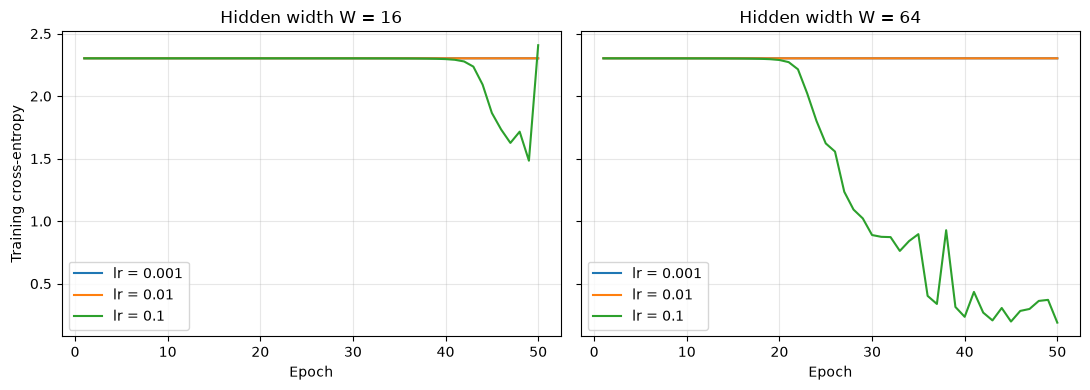

In [8]:
print(" W      lr    train loss    train acc     test acc")
for row in results:
    print(f"{row['width']:2d}   {row['learning_rate']:.3f}      "
          f"{row['train_loss']:.4f}       {row['train_accuracy']:.2%}       "
          f"{row['test_accuracy']:.2%}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, width in zip(axes, [16, 64]):
    for learning_rate in [0.001, 0.01, 0.1]:
        history = histories[(width, learning_rate)]
        ax.plot([row["epoch"] for row in history],
                [row["train_loss"] for row in history],
                label=f"lr = {learning_rate}")
    ax.set_title(f"Hidden width W = {width}")
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3)
    ax.legend()
axes[0].set_ylabel("Training cross-entropy")
fig.tight_layout()
fig.savefig("results/loss_curves.png", dpi=160)
plt.show()

## 7. Forward and backward timing

I use a batch of 32 training examples and the trained model with lr = 0.1
for each width. After 10 warm-up runs, I measure 100 forward and 100
backward passes separately and report the medians in milliseconds.
Backward timing uses a ready forward cache. It does not include another
forward pass, loss evaluation, or parameter updates.
These are local CPU measurements, so results may vary on another computer.

In [9]:
timing_rows = []
timing_samples = []
for width in [16, 64]:
    params = models[(width, 0.1)]
    X_batch, Y_batch = X_train[:32], Y_train[:32]
    for _ in range(10):
        _, cache = forward(X_batch, params)
        backward(Y_batch, params, cache)

    forward_times, backward_times = [], []
    for run in range(100):
        start = perf_counter()
        _, cache = forward(X_batch, params)
        forward_ms = (perf_counter() - start) * 1000

        start = perf_counter()
        backward(Y_batch, params, cache)
        backward_ms = (perf_counter() - start) * 1000

        forward_times.append(forward_ms)
        backward_times.append(backward_ms)
        timing_samples.append({"width": width, "run": run + 1,
                               "forward_ms": forward_ms, "backward_ms": backward_ms})

    forward_median = float(np.median(forward_times))
    backward_median = float(np.median(backward_times))
    timing_rows.append({"width": width, "batch_size": 32, "runs": 100,
                        "forward_median_ms": forward_median,
                        "backward_median_ms": backward_median,
                        "backward_over_forward": backward_median / forward_median})
    print(f"W={width}: forward={forward_median:.4f} ms, "
          f"backward={backward_median:.4f} ms, "
          f"backward/forward={backward_median / forward_median:.2f}")

save_csv("timing.csv", timing_rows)
save_csv("timing_samples.csv", timing_samples)

W=16: forward=0.0232 ms, backward=0.0252 ms, backward/forward=1.09
W=64: forward=0.0361 ms, backward=0.0470 ms, backward/forward=1.30


The forward pass has three matrix multiplications. Backpropagation has
five: three weight gradients and two multiplications to pass gradients to
earlier hidden layers. It also applies ReLU masks and sums bias gradients.
Therefore backward usually takes more time, although these small matrices
also make function overhead and memory allocation noticeable.
Increasing W makes the middle layer more expensive because it uses a W x W
weight matrix. The number of multiplications alone does not predict the
exact measured ratio.

In [10]:
best = max(results, key=lambda row: row["test_accuracy"])
print(f"Highest observed test accuracy: {best['test_accuracy']:.2%} "
      f"(W={best['width']}, lr={best['learning_rate']}).")
for row in timing_rows:
    slower = "backward" if row["backward_median_ms"] > row["forward_median_ms"] else "forward"
    print(f"For W={row['width']}, {slower} was slower in this run.")

Highest observed test accuracy: 90.74% (W=64, lr=0.1).
For W=16, backward was slower in this run.
For W=64, backward was slower in this run.


## Conclusion
In this run, the gradient check passed for 9/10 weights at W = 16 and
10/10 weights at W = 64, meeting the required threshold. The one failed
entry had a small gradient (about -2.94e-6) and an absolute difference of
about 1.5e-11. Subtracting nearly equal losses can cause this relative error.
Several sampled gradients were zero because of inactive ReLU units or
zero-valued inputs. This is a sampled check, not a proof for all parameters.

| Hidden width | Learning rate | Final test accuracy |
| --- | --- | --- |
| 16 | 0.001 | 10.19% |
| 16 | 0.01 | 10.19% |
| 16 | 0.1 | 23.89% |
| 64 | 0.001 | 10.19% |
| 64 | 0.01 | 10.19% |
| 64 | 0.1 | 90.74% |

The best observed result was W = 64 and learning rate 0.1. Its training
loss fell to 0.1883. With rates 0.001 and 0.01, loss stayed near 2.3026
and accuracy was around chance level. Small initial weights make the
early hidden-layer gradients small, so these rates made little progress
in 50 epochs.

At W = 16 and lr = 0.1, learning started late and the loss jumped on the
last epoch. A constant large learning rate and mini-batch updates can
make the loss fluctuate. I kept the final-epoch result as requested.
W = 64 learned faster here, but one split and one seed do not establish
that a wider network is always better.

Backpropagation was slower for both widths in the measured run. It needs
more matrix multiplications than the forward pass. The timing table gives
the actual medians; the exact values depend on the computer and its load.
Comparing the six test results is part of the lab. For separate tuning,
I would use a validation set and keep the test set for the final evaluation.